# Beam End-to-End — RadioSkySim

Demonstração completa do módulo **beam** do RadioSkySim, cobrindo desde a criação manual de um feixe até operações, propriedades, loaders, avaliação e visualização.

**Data:** 2026-07-26
**Branch:** LB_MVP (pós-refatoração)

## 1. Imports

Importamos as bibliotecas padrão e os módulos do RadioSkySim relevantes para o beam.

In [18]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import tempfile
from pathlib import Path
from pydantic import BaseModel

# Beam - dominio (canonico)
from radioskysims.domain.beam import Beam, BeamOps, BeamProperties
from radioskysims.domain.beam.services import BeamOperation
from radioskysims.domain.beam.models import BeamParamsDomain

# Beam - legacy (compatibilidade)
from radioskysims.beam.factory import BeamFactory
from radioskysims.beam.models import Beam as LegacyBeam

# Loaders
from radioskysims.infrastructure.beams.loaders.csv import CSVBeamLoader
from radioskysims.infrastructure.beams.loaders.custom import CustomBeamLoader

print("Todos os imports OK")
print(f"BeamOps e BeamOperation sao o mesmo: {BeamOps is BeamOperation}")

Todos os imports OK
BeamOps e BeamOperation sao o mesmo: True


## 2. Criando um Beam Manualmente

Um feixe (Beam) no RadioSkySim é um objeto que encapsula um `xr.Dataset` com dimensões `(polarization, frequency, angle)` e pelo menos a variável `amplitude`.

Vamos criar um beam com padrão gaussiano 1D para demonstração.

In [19]:
# Grade angular de -90 a 90 graus
angles = np.linspace(-90, 90, 181)
freqs = np.array([1.0e9])  # 1 GHz em Hz
pols = ["H", "V"]

# Padrao gaussiano 1D: sigma = 10 graus
amp_data = np.exp(-0.5 * (angles / 10) ** 2)

# Expande para dimensoes (polarization, frequency, angle)
amp = np.tile(amp_data, (len(pols), len(freqs), 1)).transpose(2, 1, 0)
phase = np.zeros_like(amp)

ds = xr.Dataset(
    {
        "amplitude": (("angle", "frequency", "polarization"), amp),
        "phase": (("angle", "frequency", "polarization"), phase),
    },
    coords={"angle": angles, "frequency": freqs, "polarization": pols},
)

beam = Beam(ds)
print(f"Beam criado: {beam}")
print(f"Dimensoes do dataset: {dict(beam.dataset.sizes)}")
print(f"Coords: {list(beam.dataset.coords)}")
print(f"Data vars: {list(beam.dataset.data_vars)}")

Beam criado: <radioskysims.domain.beam.models.Beam object at 0x7e1accaf1c10>
Dimensoes do dataset: {'angle': 181, 'frequency': 1, 'polarization': 2}
Coords: ['angle', 'frequency', 'polarization']
Data vars: ['amplitude', 'phase']


## 3. Visualização do Beam Original

Plot do padrão de feixe para cada polarização.

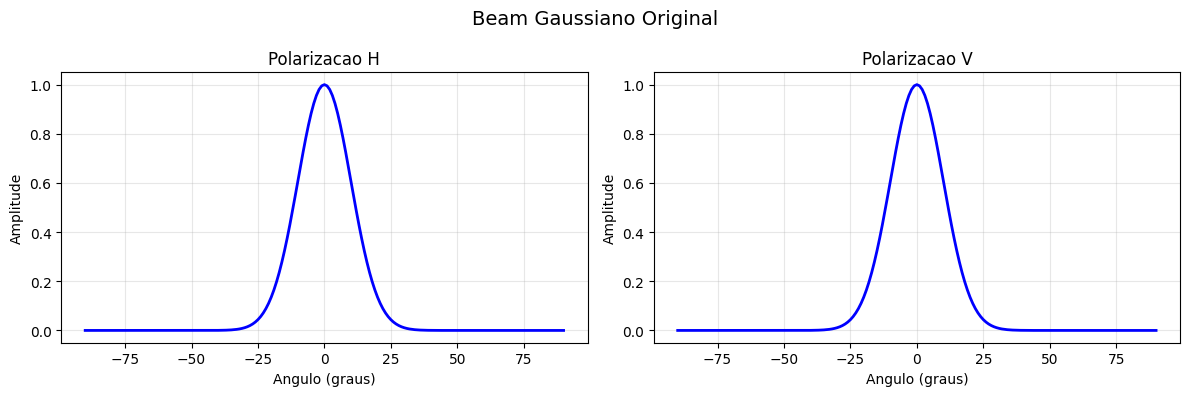

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for i, pol in enumerate(pols):
    ax = axes[i]
    amp_pol = beam.dataset.sel(polarization=pol, frequency=1.0e9)["amplitude"]
    ax.plot(beam.dataset.angle, amp_pol, "b-", linewidth=2)
    ax.set_title(f"Polarizacao {pol}")
    ax.set_xlabel("Angulo (graus)")
    ax.set_ylabel("Amplitude")
    ax.grid(True, alpha=0.3)

fig.suptitle("Beam Gaussiano Original", fontsize=14)
plt.tight_layout()
plt.show()

## 4. Beam Operations

O módulo beam oferece 4 operações fundamentais através de `BeamOperation` (ou seu alias `BeamOps`):

1. **normalize** — normaliza a amplitude pelo valor máximo
2. **slice_angular_range** — fatia o beam em um intervalo angular
3. **interpolate_angular_range** — interpola em novos ângulos (grade mais fina)
4. **symmetrize** — simetriza o padrão pela média com versão invertida

Slice: 61 pontos (original: 181)
Interpolado: 121 pontos


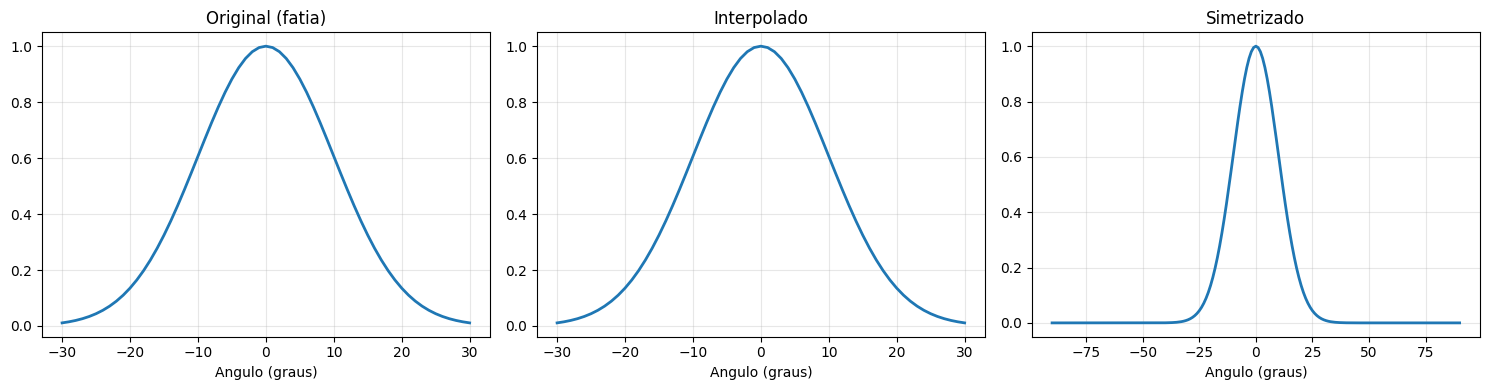

In [21]:
# 4a - Slice angular: manter apenas -30 a 30 graus
beam_sliced = BeamOps.slice_angular_range(beam, -30, 30)
print(
    f"Slice: {len(beam_sliced.dataset.angle)} pontos (original: {len(beam.dataset.angle)})"
)

# 4b - Interpolar em grade mais fina (0.5 grau)
new_angles = np.linspace(-30, 30, 121)
beam_interp = BeamOps.interpolate_angular_range(beam_sliced, new_angles)
print(f"Interpolado: {len(beam_interp.dataset.angle)} pontos")

# 4c - Simetrizar
beam_sym = BeamOps.symmetrize(beam)

# Plot comparativo
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
opts = [
    ("Original (fatia)", beam_sliced),
    ("Interpolado", beam_interp),
    ("Simetrizado", beam_sym),
]
for ax, (title, b) in zip(axes, opts):
    amp = b.dataset.sel(polarization="H", frequency=1.0e9)["amplitude"]
    ax.plot(b.dataset.angle, amp, linewidth=2)
    ax.set_title(title)
    ax.set_xlabel("Angulo (graus)")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Beam Properties

O `BeamProperties` calcula métricas físicas do feixe:

- **FWHM** (Full Width at Half Maximum) — largura à meia altura
- **Directivity** — diretividade linear e em dB
- **Main lobe directivity** — diretividade do lóbulo principal
- **Main lobe efficiency** — eficiência do lóbulo principal

In [22]:
# Calcula propriedades via metodo estatico
props = BeamProperties.compute_properties(beam.dataset)
print("Propriedades calculadas:")
for var in props.data_vars:
    print(f"  {var}:")
    print(props[var].values)

# Metodo conveniente no proprio Beam
params = beam.params()
print(f"\nBeamParamsDomain (Pydantic):")
print(f"  FWHM: {params.fwhm}")
print(f"  Directivity (linear): {params.directivity:.2f}")
print(f"  Directivity (dB): {params.directivity_db:.2f}")
print(f"  Main lobe efficiency: {params.main_lobe_efficiency:.3f}")
print(f"  Tipo: {type(params).__name__}")
print(f"  Herda de BaseModel: {isinstance(params, BaseModel)}")

Propriedades calculadas:
  fwhm:
[[16.]
 [16.]]
  directivity:
[[20.31082501]
 [20.31082501]]
  main_lobe_directivity:
[[26.34155269]
 [26.34155269]]
  directivity_db:
[[13.07727564]
 [13.07727564]]
  main_lobe_efficiency:
[[0.77105648]
 [0.77105648]]

BeamParamsDomain (Pydantic):
  FWHM: [[16.]
 [16.]]
  Directivity (linear): 20.31
  Directivity (dB): 13.08
  Main lobe efficiency: 0.771
  Tipo: BeamParamsDomain
  Herda de BaseModel: True


## 6. Beam Evaluation

O método `evaluate()` interpola o beam em frequências e ângulos arbitrários, com heurísticas automáticas de conversão de unidades (radianos/graus, MHz/Hz).

Resultado shape: (121, 1, 2), dims: ('angle', 'frequency', 'polarization')


/media/lbarosi/barosi_portable1/RadioSkySim/.venv/lib/python3.13/site-packages/scipy/interpolate/_interpolate.py:514: RuntimeWarning: invalid value encountered in divide
  ((x_new - x_lo)/(x_hi - x_lo))[:, None] * y_hi
/media/lbarosi/barosi_portable1/RadioSkySim/.venv/lib/python3.13/site-packages/scipy/interpolate/_interpolate.py:515: RuntimeWarning: invalid value encountered in divide
  + ((x_hi - x_new)/(x_hi - x_lo))[:, None] * y_lo


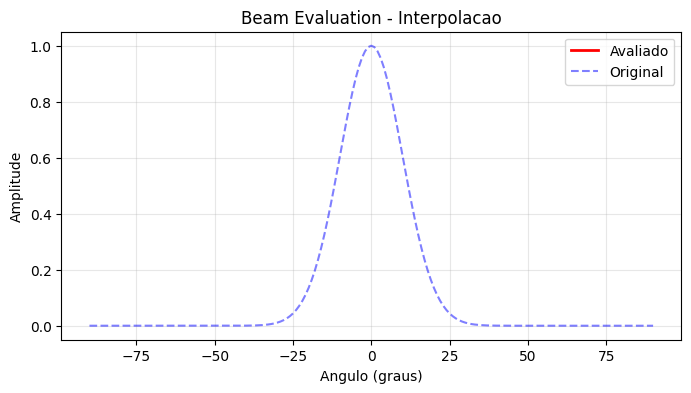

In [23]:
# Avaliar o beam em novos angulos (grade fina) e frequencia especifica
eval_angles = xr.DataArray(np.linspace(-30, 30, 121), dims="angle")
eval_freqs = xr.DataArray([1.0e9], dims="frequency")

result = beam.evaluate(angle=eval_angles, frequency=eval_freqs)

# Result da avaliacao tem dims (angle, frequency, polarization)
print(f"Resultado shape: {result.shape}, dims: {result.dims}")

# Selecionar pelo indice (mais robusto que por label)
result_plot = result.isel(frequency=0, polarization=0)

# Plot
plt.figure(figsize=(8, 4))
plt.plot(eval_angles, result_plot, "r-", linewidth=2, label="Avaliado")
plt.plot(
    beam.dataset.angle,
    beam.dataset.sel(polarization="H", frequency=1.0e9)["amplitude"],
    "b--",
    alpha=0.5,
    label="Original",
)
plt.xlabel("Angulo (graus)")
plt.ylabel("Amplitude")
plt.title("Beam Evaluation - Interpolacao")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 7. Loaders

Os loaders em `infrastructure/beams/loaders/` permitem carregar beams de diferentes fontes.

### 7a. CSVBeamLoader

Carrega dados tabulares de arquivos CSV.

In [24]:
# Criar CSV temporario
csv_data = {
    "polarization": ["H", "H", "H", "H", "H"],
    "frequency": [1.0e9, 1.0e9, 1.0e9, 1.0e9, 1.0e9],
    "angle": [-20, -10, 0, 10, 20],
    "amplitude": [0.3, 0.8, 1.0, 0.8, 0.3],
}
csv_path = Path(tempfile.mktemp(suffix=".csv"))
pd.DataFrame(csv_data).to_csv(csv_path, index=False)

# Carregar
loader = CSVBeamLoader(str(csv_path))
beam_csv = loader.load()
print(f"CSVBeamLoader: {beam_csv}")
print(f"  Polarizacoes: {beam_csv.dataset.polarization.values}")
print(f"  Amplitude max: {beam_csv.dataset['amplitude'].max().item():.2f}")

# Limpeza
csv_path.unlink()

CSVBeamLoader: <radioskysims.domain.beam.models.Beam object at 0x7e1accc2b570>
  Polarizacoes: ['H']
  Amplitude max: 1.00


### 7b. CustomBeamLoader

Carrega um beam a partir de um módulo Python com funções `amplitude(pol, freq, angle)` e `phase(pol, freq, angle)`.

In [25]:
# Criar modulo Python temporario
module_code = """
def amplitude(pol, freq, angle):
    return max(0.0, 1.0 - abs(angle) / 30.0)

def phase(pol, freq, angle):
    return angle * 0.01
"""
module_path = Path(tempfile.mktemp(suffix=".py"))
module_path.write_text(module_code)

# Carregar
loader = CustomBeamLoader(module_path, ["H", "V"], [1.0e9], [-20, 0, 20])
beam_custom = loader.load()
print(f"CustomBeamLoader: {beam_custom}")
print(f"  Shape amplitude: {beam_custom.dataset['amplitude'].shape}")
print(f"  Tem phase: {'phase' in beam_custom.dataset.data_vars}")

# Limpeza
module_path.unlink()

CustomBeamLoader: <radioskysims.domain.beam.models.Beam object at 0x7e1acc0c5250>
  Shape amplitude: (2, 1, 3)
  Tem phase: True


## 8. BeamFactory (Legado)

O `BeamFactory` do namespace `radioskysims.beam` oferece beams teóricos para testes rápidos e compatibilidade com código legado.

Beams teoricos criados!


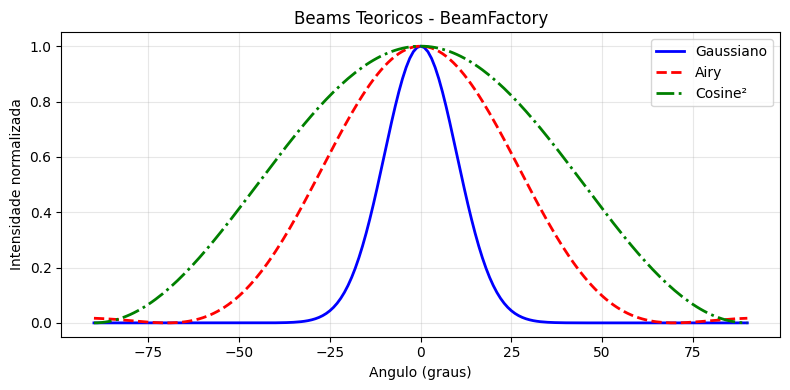

In [26]:
import importlib
import radioskysims.beam.factory

importlib.reload(radioskysims.beam.factory)
from radioskysims.beam.factory import BeamFactory

# Criar 3 tipos de beam
beam_gaussian = BeamFactory.create_predefined_beam("Gauss", "gaussian", frequency=1.0)
beam_airy = BeamFactory.create_predefined_beam("Airy", "airy", frequency=1.0)
beam_cosine = BeamFactory.create_predefined_beam("Cos", "tapered_cosine", frequency=1.0)

print("Beams teoricos criados!")

# Plot comparativo
fig, ax = plt.subplots(figsize=(8, 4))
for b, label, style in [
    (beam_gaussian, "Gaussiano", "b-"),
    (beam_airy, "Airy", "r--"),
    (beam_cosine, "Cosine²", "g-."),
]:
    amp = b.dataset.sel(polarization="H", frequency=1.0)["amplitude"]
    ax.plot(b.dataset.angle, amp, style, linewidth=2, label=label)

ax.set_xlabel("Angulo (graus)")
ax.set_ylabel("Intensidade normalizada")
ax.set_title("Beams Teoricos - BeamFactory")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Pipeline Completo

Fluxo científico típico: criar beam → operar → calcular propriedades → visualizar.

=== Pipeline Completo ===
FWHM:          [[12. 12.]
 [12. 12.]] graus
Diretividade:  25.39 (14.0 dB)
Eficiencia:    0.750


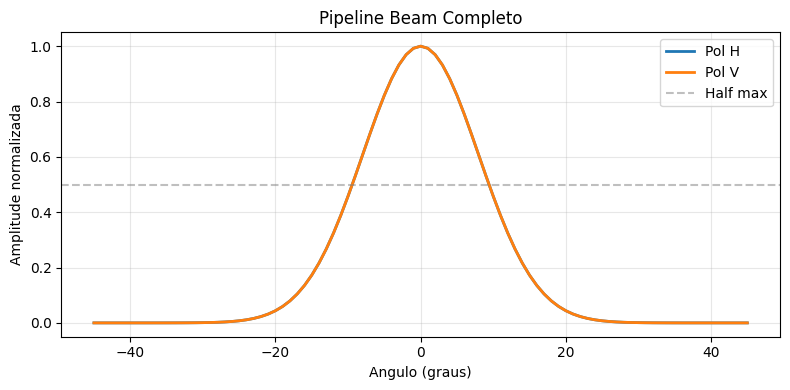


BeamParamsDomain (Pydantic):
{'polarizations': ['H', 'V'], 'frequencies': [1000000000.0, 1100000000.0], 'has_phase': False, 'fwhm': array([[12., 12.],
       [12., 12.]]), 'directivity': 25.388531259649053, 'main_lobe_directivity': 33.84768011008271, 'main_lobe_efficiency': 0.750081871994713, 'directivity_db': 14.04637577428277}


In [27]:
# 1. Criar beam com padrao
angles = np.linspace(-90, 90, 181)
amp = np.exp(-0.5 * (angles / 8) ** 2)  # sigma = 8 graus
amp_3d = np.tile(amp, (2, 2, 1)).transpose(2, 1, 0)  # 2 pols, 2 freqs

ds_pipeline = xr.Dataset(
    {"amplitude": (("angle", "frequency", "polarization"), amp_3d)},
    coords={
        "angle": angles,
        "frequency": [1.0e9, 1.1e9],
        "polarization": ["H", "V"],
    },
)
b = Beam(ds_pipeline)

# 2. Operacoes
b = BeamOps.normalize(b)
b = BeamOps.slice_angular_range(b, -45, 45)

# 3. Propriedades
params = b.params()
print(f"=== Pipeline Completo ===")
print(f"FWHM:          {np.round(params.fwhm, 2)} graus")
print(f"Diretividade:  {params.directivity:.2f} ({params.directivity_db:.1f} dB)")
print(f"Eficiencia:    {params.main_lobe_efficiency:.3f}")

# 4. Visualizacao final
fig, ax = plt.subplots(figsize=(8, 4))
for pol in ["H", "V"]:
    amp_pol = b.dataset.sel(polarization=pol, frequency=1.0e9)["amplitude"]
    ax.plot(b.dataset.angle, amp_pol, linewidth=2, label=f"Pol {pol}")
ax.axhline(0.5, color="gray", linestyle="--", alpha=0.5, label="Half max")
ax.set_xlabel("Angulo (graus)")
ax.set_ylabel("Amplitude normalizada")
ax.set_title("Pipeline Beam Completo")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nBeamParamsDomain (Pydantic):")
print(params.model_dump() if hasattr(params, "model_dump") else params)